<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lesson 03 · Applied AI: unstructured data</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">01 · Text Mining basics: SMS spam</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">How does text become numbers?</p>
</div>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/03-applied-ai-projects/blob/main/01_text_mining/01_mini_project_sms_spam/01_Text_Mining_Basics_SMS_Spam.ipynb) [![Slides](https://img.shields.io/badge/slides-Lesson_03-ffd43b)](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#sms-spam)

## 🎯 Objectives
By the end of this notebook you will be able to:

- explain how a sentence becomes a row of numbers: **tokens → vocabulary → bag of words**;
- compute **TF-IDF** by hand on a tiny corpus and check it against scikit-learn;
- measure how close two texts are with **cosine similarity**;
- build a real **spam filter** (5,574 SMS) with a `Pipeline` of `TfidfVectorizer` + **Naive Bayes** / **Logistic Regression**;
- read what the model learned (its "spam words"), look at its mistakes and test it with **your own messages**.

**⏱️ Duration:** ≈ 60 min · **📋 Prerequisites:** Lesson 02 (train/test split, `Pipeline`, precision/recall/F1, confusion matrix) · **▶️ How to use:** run the cells in order with `Shift`+`Enter`; try the ✏️ exercises before opening the solutions.

## 📑 Contents

1. [🧩 Why text is different](#sec-1)
2. [🔤 Tokens and vocabulary](#sec-2)
3. [🧮 Bag of words](#sec-3)
4. [⚖️ TF-IDF by hand](#sec-4)
5. [📐 Cosine similarity: how close are two texts?](#sec-5)
6. [📱 Mini-project: the SMS Spam Collection](#sec-6)
7. [🤖 Two spam filters: Naive Bayes and Logistic Regression](#sec-7)
8. [🔍 What did the model learn, and where does it fail?](#sec-8)
9. [✍️ Try your own messages](#sec-9)
10. [📌 Summary](#sec-10)
11. [📚 Learn more](#sec-11)

<a id="sec-0"></a>
## ⚙️ Setup

In [1]:
# ⚙️ Setup: works locally (VS Code / Jupyter) and in Google Colab
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/03-applied-ai-projects")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/03-applied-ai-projects.git", str(ROOT)], check=True)
    try:
        import wordcloud  # noqa: F401  (Colab usually has it already)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wordcloud"], check=True)
else:  # locally: walk up until we find the folder that has src/ and data/
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())

sys.path.insert(0, str(ROOT))
print("Project root:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Project root: 03-applied-ai-projects (local)


In [2]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

from src.paths import data_dir
from src.plotting import CLASS_COLORS, PALETTE, apply_style, label_bars, plot_confusion, save_fig
from src.text import top_coefficients

apply_style()
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)

# Only the authors use this (EXPORT_SLIDES=1) to refresh the images in the slide deck.
EXPORT_SLIDES = os.environ.get("EXPORT_SLIDES") == "1"
def save_slide(fig, name):
    if EXPORT_SLIDES:
        save_fig(fig, ROOT / "assets" / "slides" / f"{name}.png")

print("Ready. No GPU needed for this notebook: everything runs in seconds on a laptop CPU.")

Ready. No GPU needed for this notebook: everything runs in seconds on a laptop CPU.


<a id="sec-1"></a>
# 1. 🧩 Why text is different

In Lesson 02 every row of a table had **columns of numbers**: age, fare, number of rooms. A model multiplies numbers, so that was easy.

Text has no columns. *"Win a free phone now!"* is just a string of characters, and two messages never have the same length. Before any model can learn, we need a recipe that turns **any text into a fixed list of numbers**. That recipe is the heart of **Text Mining**.

> 🧠 **How it works (the big idea)**
> 1. **Cut** the text into pieces (*tokens*), usually words.
> 2. **List** every different token we have seen: the *vocabulary*. Each token gets its own column.
> 3. **Count** (or weigh) how much each token appears in each text. One text = one row.
> 4. Now it is a table again, and everything from Lesson 02 works: split, `Pipeline`, metrics, threshold.
>
> **Analogy:** a supermarket receipt. It doesn't say in which order you put things in the basket, only *how many* of each product you bought. The receipt is still a great summary of your shopping.

> 📖 **Mini-glossary**
> - **Corpus**: the collection of texts we work with (here: 6 sentences, then 5,574 SMS).
> - **Document**: one text of the corpus (a sentence, an SMS, a tweet).
> - **Token**: a piece of text, usually a word (sometimes a number, an emoji or a punctuation mark).
> - **Vocabulary**: the list of different tokens in the corpus; its size = number of columns.
> - **Stop words**: very common words (*the, a, is, to*) that carry little meaning on their own.

We start with a **toy corpus**: six short sentences we wrote ourselves. Four of them could be normal messages and two look like spam. Small enough to see every number.

In [3]:
corpus = [
    "I love this phone",
    "I love my new phone, it is great",
    "This phone is terrible",
    "Win a free phone now",
    "Free prize! Call now to win",
    "Call me when you are free",
]
names = [f"S{i}" for i in range(1, len(corpus) + 1)]  # short names for the plots
for name, sentence in zip(names, corpus):
    print(f"{name}: {sentence}")

S1: I love this phone
S2: I love my new phone, it is great
S3: This phone is terrible
S4: Win a free phone now
S5: Free prize! Call now to win
S6: Call me when you are free


<a id="sec-2"></a>
# 2. 🔤 Tokens and vocabulary

**Tokenising** = cutting a text into tokens. The simplest rule: put everything in lower case and keep the runs of letters and digits. Punctuation disappears, *"Phone"* and *"phone"* become the same token.

In [4]:
def simple_tokenize(text):
    """Lower case, then keep runs of letters/digits (punctuation is dropped)."""
    return re.findall(r"\w+", text.lower())

tokens = [simple_tokenize(s) for s in corpus]
for name, toks in zip(names, tokens):
    print(f"{name}: {toks}")

vocabulary = sorted(set(t for toks in tokens for t in toks))
print(f"\nVocabulary: {len(vocabulary)} different tokens")
print(vocabulary)

S1: ['i', 'love', 'this', 'phone']
S2: ['i', 'love', 'my', 'new', 'phone', 'it', 'is', 'great']
S3: ['this', 'phone', 'is', 'terrible']
S4: ['win', 'a', 'free', 'phone', 'now']
S5: ['free', 'prize', 'call', 'now', 'to', 'win']
S6: ['call', 'me', 'when', 'you', 'are', 'free']

Vocabulary: 21 different tokens
['a', 'are', 'call', 'free', 'great', 'i', 'is', 'it', 'love', 'me', 'my', 'new', 'now', 'phone', 'prize', 'terrible', 'this', 'to', 'when', 'win', 'you']


Six sentences, 33 words in total, but only **21 different tokens**: *phone* appears in four sentences, *free* in three. In a real corpus the vocabulary grows to **tens of thousands** of tokens, and that number becomes the number of columns of our table.

> 💡 Tokenising is a **choice**, not a law. Should *"don't"* be one token or two? Keep emojis 😀 and `!!!`? Keep numbers like `87121` (a premium SMS number)? For spam those choices matter, and we will see the model use them.

<a id="sec-3"></a>
# 3. 🧮 Bag of words

> 🧠 **How it works: bag of words (BoW)**
> - **Idea:** a text is described only by *which* words it contains and *how many times*.
> - **Steps:** one column per vocabulary token → for each sentence, count each token → a table *documents × tokens*.
> - **Analogy:** pour the words of the sentence into a bag and shake it: the order is gone, the counts stay.
> - **Limits:** *"dog bites man"* and *"man bites dog"* get the **same** row; most cells are 0 (a *sparse* matrix); synonyms (*great* / *awesome*) are unrelated columns.

scikit-learn does all of this with `CountVectorizer`: `fit` learns the vocabulary, `transform` counts. (We tell it to keep one-letter words like *I* and *a* so that the table matches our hand-made vocabulary.)

In [5]:
count_vec = CountVectorizer(token_pattern=r"(?u)\b\w+\b")   # keep 1-letter words too
bow = count_vec.fit_transform(corpus)                          # sparse matrix: 6 rows × 21 columns
bow_table = pd.DataFrame(bow.toarray(), index=names, columns=count_vec.get_feature_names_out())
print("Shape:", bow.shape, f"· share of zeros: {1 - bow.nnz / np.prod(bow.shape):.0%}")
bow_table

Shape: (6, 21) · share of zeros: 74%


,a,are,call,free,great,i,is,it,love,me,...,new,now,phone,prize,terrible,this,to,when,win,you
S1,0,0,0,0,0,1,0,0,1,0,...,0,0,1,0,0,1,0,0,0,0
S2,0,0,0,0,1,1,1,1,1,0,...,1,0,1,0,0,0,0,0,0,0
S3,0,0,0,0,0,0,1,0,0,0,...,0,0,1,0,1,1,0,0,0,0
S4,1,0,0,1,0,0,0,0,0,0,...,0,1,1,0,0,0,0,0,1,0
S5,0,0,1,1,0,0,0,0,0,0,...,0,1,0,1,0,0,1,0,1,0
S6,0,1,1,1,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,1


The same table, as a picture. Each **row is a sentence**, each **column a word**, and the colour shows the count.

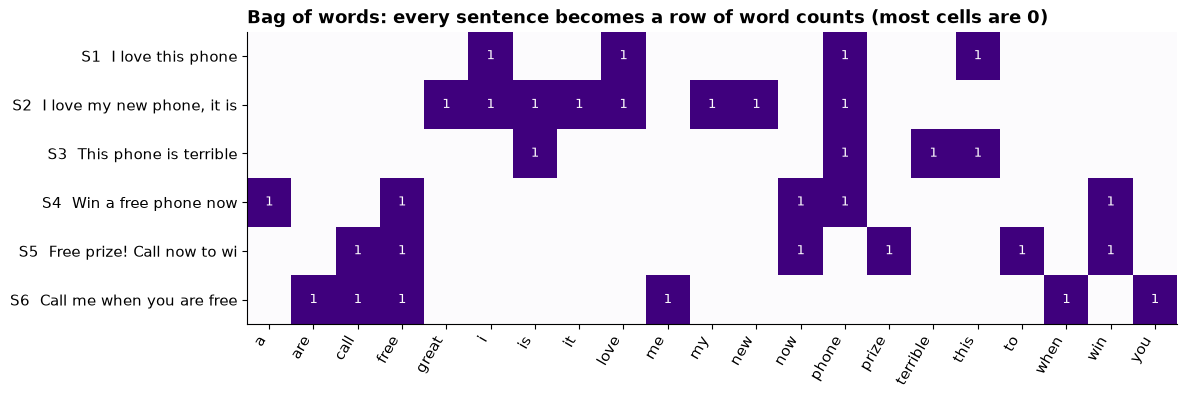

In [6]:
def matrix_heatmap(table, ax, fmt="{:.0f}", cmap="Purples", vmax=None):
    """Colour a documents × words table and write every non-zero value inside its cell."""
    values = table.to_numpy(dtype=float)
    vmax = vmax or values.max()
    ax.imshow(values, cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            if values[i, j] > 0:
                ax.text(j, i, fmt.format(values[i, j]), ha="center", va="center", fontsize=9,
                        color="white" if values[i, j] > 0.6 * vmax else PALETTE["navy"])
    ax.set_xticks(range(values.shape[1]), table.columns, rotation=60, ha="right")
    ax.set_yticks(range(values.shape[0]), [f"{n}  {s[:26]}" for n, s in zip(table.index, corpus)])
    ax.grid(False)
    return ax

fig, ax = plt.subplots(figsize=(12, 3.8))
matrix_heatmap(bow_table, ax)
ax.set_title("Bag of words: every sentence becomes a row of word counts (most cells are 0)")
plt.show()
save_slide(fig, "tm-bag-of-words")

Look at the columns: *phone* lights up in four sentences, so it tells us almost nothing about *which* sentence we are reading. *Prize* and *terrible* appear once each: they are **rare and very informative**. Counting treats both kinds of words the same. TF-IDF fixes that.

### ✏️ Exercise 1 — Word order is lost (Difficulty ⭐)
Use `count_vec.transform([...])` to turn *"dog bites man"* and *"man bites dog"* into rows. Are the two rows equal? (Careful: none of these words is in our vocabulary! Fit a new `CountVectorizer` on these two sentences.)

In [7]:
# TODO: fit a CountVectorizer on the two sentences and compare their rows
pair = ["dog bites man", "man bites dog"]

<details>
<summary>💡 Show solution</summary>

```python
pair = ["dog bites man", "man bites dog"]
vec = CountVectorizer()
rows = vec.fit_transform(pair).toarray()
print(vec.get_feature_names_out(), rows)
print("Same row?", (rows[0] == rows[1]).all())   # True: the bag of words cannot tell them apart
```
A popular fix is to also count pairs of neighbouring words (**bigrams**, `ngram_range=(1, 2)`): *"dog bites"* and *"bites dog"* are different columns. We will use bigrams with the tweets in notebook 02.
</details>

<a id="sec-4"></a>
# 4. ⚖️ TF-IDF by hand

> 🧠 **How it works: TF-IDF** (*term frequency × inverse document frequency*)
> - **Idea:** a word is important for a text if it appears **often in this text** (TF) but **rarely in the others** (IDF).
> - **Steps:**
>   1. **TF** = how many times the word appears in the document (the bag-of-words count).
>   2. **DF** = in how many documents the word appears.
>   3. **IDF** = $\ln\frac{1 + n}{1 + \text{DF}} + 1$, with $n$ = number of documents. Rare word → big IDF; word in every document → IDF close to 1.
>   4. **TF × IDF**, then divide the row by its length (L2 norm) so that long and short texts are comparable.
> - **Analogy:** at a party where everyone wears jeans, "jeans" doesn't help you find your friend. "Red hat" does.
> - **Limits:** still a bag (no word order, no synonyms); IDF depends on the corpus you trained on.

Let's compute it for **S4 · "Win a free phone now"**, one step per column.

In [8]:
n_docs = len(corpus)
tf = bow_table                                   # step 1: counts
df = (bow_table > 0).sum(axis=0)                 # step 2: in how many sentences?
idf = np.log((1 + n_docs) / (1 + df)) + 1        # step 3: rare words get a bigger weight
tfidf_raw = tf * idf                             # step 4a
tfidf_hand = tfidf_raw.div(np.sqrt((tfidf_raw ** 2).sum(axis=1)), axis=0)  # step 4b: unit length

s4 = [w for w in bow_table.columns if bow_table.loc["S4", w] > 0]
pd.DataFrame({"TF (count)": tf.loc["S4", s4], "DF (sentences)": df[s4], "IDF": idf[s4].round(3),
              "TF × IDF": tfidf_raw.loc["S4", s4].round(3), "TF-IDF (normalised)": tfidf_hand.loc["S4", s4].round(3)}
             ).sort_values("TF-IDF (normalised)", ascending=False)

,TF (count),DF (sentences),IDF,TF × IDF,TF-IDF (normalised)
a,1,1,2.253,2.253,0.561
now,1,2,1.847,1.847,0.460
win,1,2,1.847,1.847,0.460
free,1,3,1.560,1.560,0.388
phone,1,4,1.336,1.336,0.333


All four words appear **once** in S4, yet they end with different weights: *a* (only in S4) gets the highest value, *phone* (in 4 of the 6 sentences) the lowest. TF-IDF has learned, without any dictionary, that *phone* is a "jeans" word in this corpus.

> ⚠️ Notice that *a* wins here only because our corpus is tiny. In real corpora *a* is everywhere and its IDF drops; that is also why we often remove **stop words**.

Now the same thing with scikit-learn's `TfidfVectorizer` (its default formula is exactly ours):

Same numbers as our hand-made version? True


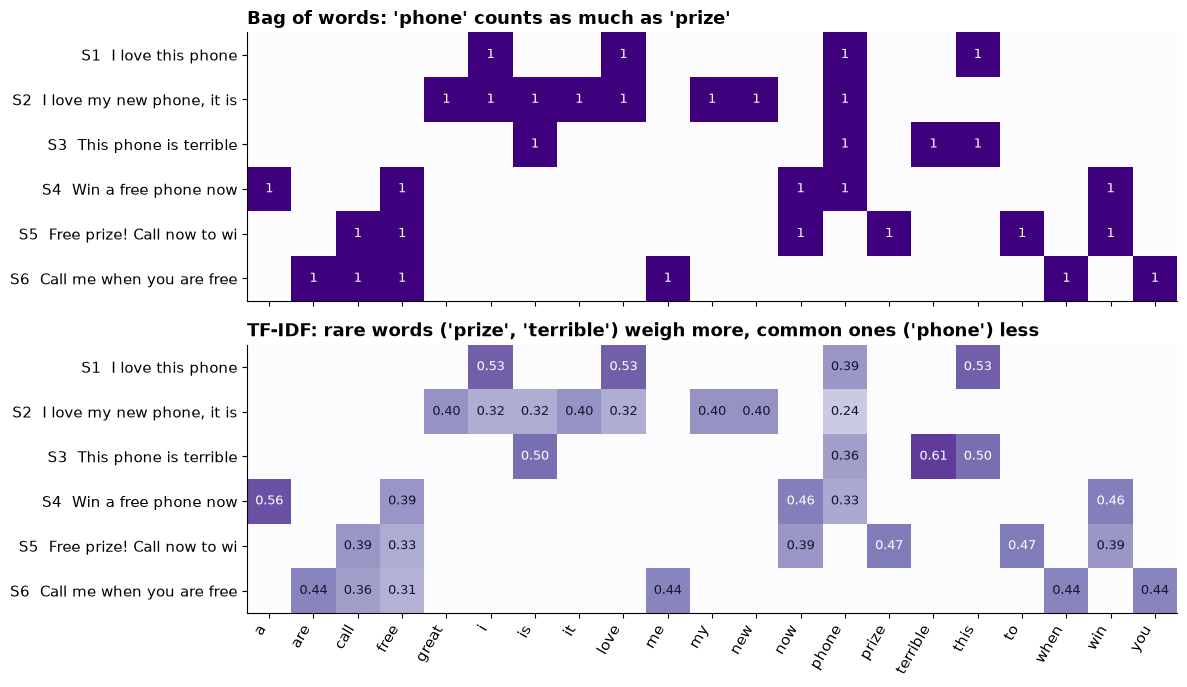

In [9]:
tfidf_vec = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")
tfidf = tfidf_vec.fit_transform(corpus)
tfidf_table = pd.DataFrame(tfidf.toarray(), index=names, columns=tfidf_vec.get_feature_names_out())
print("Same numbers as our hand-made version?", np.allclose(tfidf_table, tfidf_hand))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
matrix_heatmap(bow_table, axes[0])
axes[0].set_title("Bag of words: 'phone' counts as much as 'prize'")
matrix_heatmap(tfidf_table, axes[1], fmt="{:.2f}", vmax=0.75)
axes[1].set_title("TF-IDF: rare words ('prize', 'terrible') weigh more, common ones ('phone') less")
fig.tight_layout()
plt.show()
save_slide(fig, "tm-bow-vs-tfidf")

<a id="sec-5"></a>
# 5. 📐 Cosine similarity: how close are two texts?

Each sentence is now a **vector** (an arrow) in a space with 21 dimensions, one per word. Two sentences that use the same rare words point in **the same direction**.

> 🧠 **How it works: cosine similarity**
> - **Idea:** measure the *angle* between two vectors, not their length. Same direction → 1, nothing in common → 0.
> - **Formula:** $\cos(a, b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}$. Our TF-IDF rows already have length 1, so it is just the sum of the products of matching cells.
> - **Analogy:** two people pointing at the same star, one with a short arm and one with a long arm: same direction, same star.
> - **Used for:** search engines ("which documents are closest to my query?"), duplicate detection, recommendations. In notebook 05 we will do the same with *embeddings*.

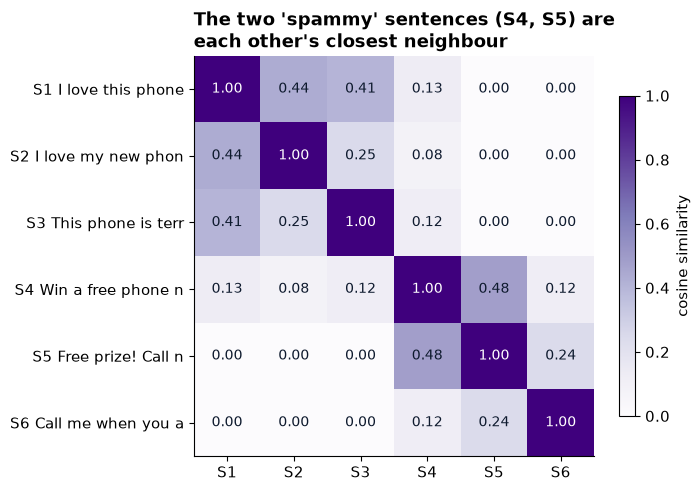

In [10]:
sim = cosine_similarity(tfidf)
fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(sim, cmap="Purples", vmin=0, vmax=1)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=10,
                color="white" if sim[i, j] > 0.6 else PALETTE["navy"])
labels = [f"{n} {s[:18]}" for n, s in zip(names, corpus)]
ax.set_xticks(range(len(names)), names)
ax.set_yticks(range(len(names)), labels)
ax.grid(False)
ax.set_title("The two 'spammy' sentences (S4, S5) are\neach other's closest neighbour")
fig.colorbar(im, ax=ax, shrink=0.8, label="cosine similarity")
plt.show()
save_slide(fig, "tm-cosine-similarity")

Read the matrix row by row: the diagonal is 1 (every sentence is identical to itself). S1 and S2 (*"I love … phone"*) are close; S4 and S5 share *win*, *free* and *now*. S3 (*terrible*) shares only *this*, *phone* and *is* with the others.

That simple trick is already a tiny **search engine**: turn the query into a TF-IDF row with the *same* vectoriser, then sort the sentences by similarity.

In [11]:
def search(query, k=3):
    """Return the k sentences of the toy corpus that are most similar to the query."""
    q = tfidf_vec.transform([query])                 # same vocabulary and IDF as the corpus
    scores = cosine_similarity(q, tfidf).ravel()
    order = scores.argsort()[::-1][:k]
    return pd.DataFrame({"sentence": [corpus[i] for i in order], "similarity": scores[order].round(3)})

search("free prize phone")

,sentence,similarity
0,Free prize! Call now to win,0.516
1,Win a free phone now,0.345
2,I love this phone,0.169


### ✏️ Exercise 2 — Words the search engine has never seen (Difficulty ⭐)
Search for *"I adore this mobile"*. What do you get, and why? What does that tell you about the limits of bag-of-words?

In [12]:
# TODO: try search("I adore this mobile") and explain the scores

<details>
<summary>💡 Show solution</summary>

```python
search("I adore this mobile")
```
Only *i* and *this* are in the vocabulary, so S1 *"I love this phone"* comes first, but only because of *i* and *this*. *adore* and *mobile* are unknown words: they get no column and are silently ignored. Bag-of-words knows nothing about **meaning**: *adore* ≈ *love* and *mobile* ≈ *phone* are invisible to it. Sentence **embeddings** (notebook 02, section 5, and notebook 05) solve exactly this.
</details>

<a id="sec-6"></a>
# 6. 📱 Mini-project: the SMS Spam Collection

Time for real data. Your phone's spam filter needs to decide, for every new SMS, *ham* (a normal message) or *spam*.

### 🗂️ Meet the data

| | |
|---|---|
| **What** | 5,574 real English SMS messages, each tagged `ham` or `spam` |
| **Source** | Almeida & Hidalgo (2011), *SMS Spam Collection*, UCI Machine Learning Repository ([link](https://archive.ics.uci.edu/dataset/228/sms+spam+collection)), licence CC BY 4.0 |
| **File** | `data/sms_spam/sms_spam.csv` (committed in the repository, 480 KB) |
| **One row =** | one SMS · **Target =** `label` |

More details in the [data dictionary](../../data/DATA_DICTIONARY.md#sms-spam-collection-sms_spam).

In [13]:
sms = pd.read_csv(data_dir() / "sms_spam" / "sms_spam.csv")
print(sms.shape)
display(sms.sample(6, random_state=3))
print(sms["label"].value_counts().to_string())

(5574, 2)


,label,text
2155,ham,Oh god i am happy to see your message after 3 days
4072,ham,I've reached home n i bathe liao... U can call me now...
615,ham,I called and said all to him:)then he have to choose this future.
3816,ham,"Not yet chikku..k, then wat abt tht guy did he stopped irritating or msging to u.."
1927,ham,"Dont give a monkeys wot they think and i certainly don't mind. Any friend of mine&all that! Just don't sleep wiv , t..."
2391,ham,First has she gained more than &lt;#&gt; kg since she took in. Second has she done the blood sugar tests. If she ha...


label
ham     4827
spam     747


**Duplicates.** Many messages repeat (spam campaigns are sent to thousands of people; *"Sorry, I'll call later"* is a phone shortcut). If the same text lands in train **and** test, the model is tested on something it has already memorised: a mild form of the **leakage** we met in Lesson 02. We drop exact duplicates *before* splitting.

In [14]:
n_before = len(sms)
sms = sms.drop_duplicates("text").reset_index(drop=True)
print(f"Removed {n_before - len(sms)} duplicated messages → {len(sms):,} left")
print(f"Spam share: {(sms['label'] == 'spam').mean():.1%}")

Removed 403 duplicated messages → 5,171 left
Spam share: 12.6%


### 🔎 Explore: how do spam and ham differ?
Two quick questions before any model: are spam messages **longer**? Which **words** does each class use?

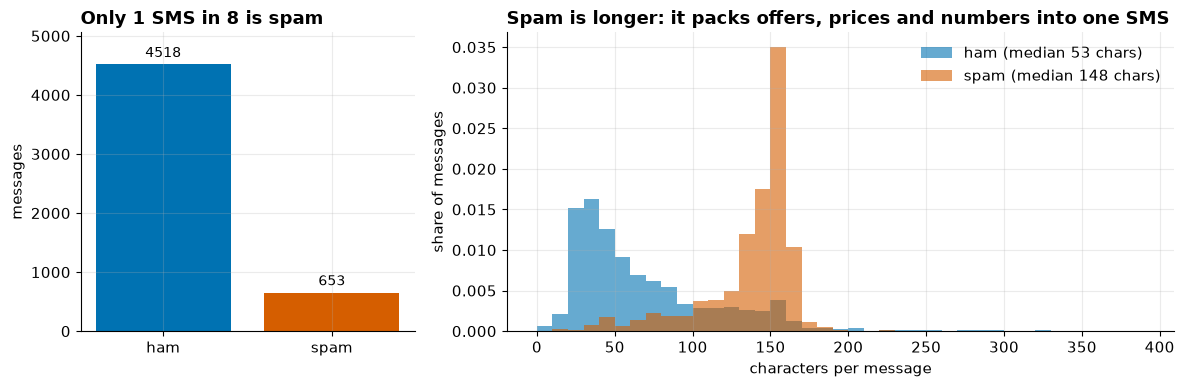

In [15]:
sms["length"] = sms["text"].str.len()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2]})
counts = sms["label"].value_counts()
axes[0].bar(counts.index, counts.values, color=[CLASS_COLORS[c] for c in counts.index])
label_bars(axes[0], counts.values, decimals=0, horizontal=False)
axes[0].set_title("Only 1 SMS in 8 is spam")
axes[0].set_ylabel("messages")
bins = np.arange(0, 400, 10)
for label in ["ham", "spam"]:
    axes[1].hist(sms.loc[sms["label"] == label, "length"], bins=bins, alpha=0.6, density=True,
                 color=CLASS_COLORS[label], label=f"{label} (median {sms.loc[sms['label'] == label, 'length'].median():.0f} chars)")
axes[1].set(xlabel="characters per message", ylabel="share of messages",
            title="Spam is longer: it packs offers, prices and numbers into one SMS")
axes[1].legend()
fig.tight_layout()
plt.show()

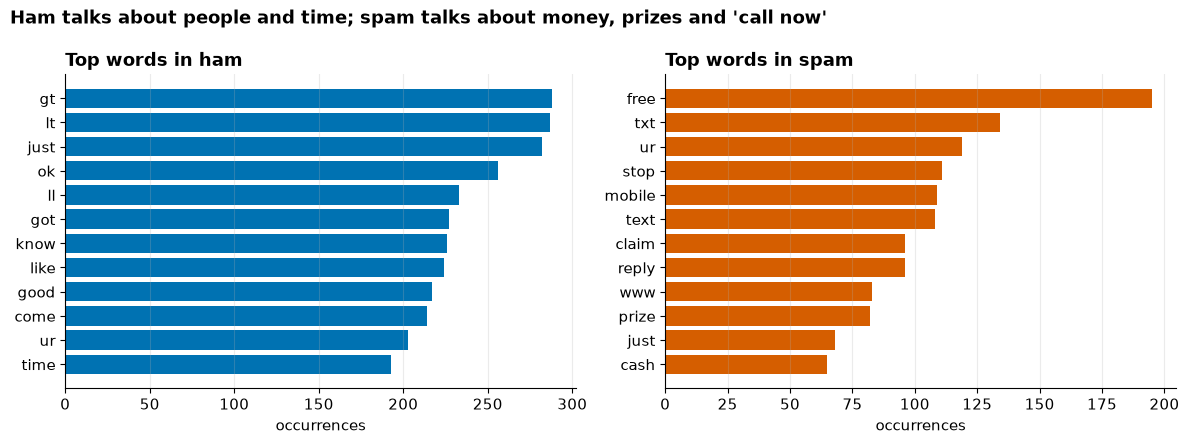

In [16]:
def top_words(texts, n=12):
    """Most frequent words of a list of texts, without English stop words."""
    vec = CountVectorizer(stop_words="english")
    counts = np.asarray(vec.fit_transform(texts).sum(axis=0)).ravel()
    order = counts.argsort()[::-1][:n]
    return pd.Series(counts[order], index=vec.get_feature_names_out()[order])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, label in zip(axes, ["ham", "spam"]):
    words = top_words(sms.loc[sms["label"] == label, "text"])[::-1]
    ax.barh(words.index, words.values, color=CLASS_COLORS[label])
    ax.set_title(f"Top words in {label}")
    ax.set_xlabel("occurrences")
    ax.grid(axis="y", visible=False)
fig.suptitle("Ham talks about people and time; spam talks about money, prizes and 'call now'",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

One picture you probably remember from Lesson 01: a **word cloud**, here of the spam messages only. Nice for a first look, but bars are easier to compare (the size of a word in a cloud is hard to read precisely).

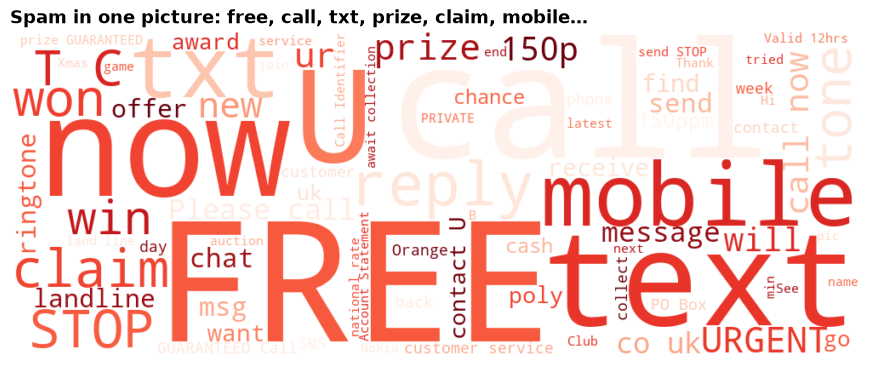

In [17]:
from wordcloud import STOPWORDS, WordCloud

spam_text = " ".join(sms.loc[sms["label"] == "spam", "text"])
cloud = WordCloud(width=1000, height=380, background_color="white", colormap="Reds", random_state=SEED,
                  stopwords=STOPWORDS, max_words=80).generate(spam_text)
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.imshow(cloud, interpolation="bilinear")
ax.axis("off")
ax.set_title("Spam in one picture: free, call, txt, prize, claim, mobile…")
plt.show()

<a id="sec-7"></a>
# 7. 🤖 Two spam filters: Naive Bayes and Logistic Regression

Same recipe as in Lesson 02: **split first** (stratified, so both parts keep ~12% spam), then put *everything that learns from data* inside a `Pipeline`. Here that includes the `TfidfVectorizer`: the vocabulary and the IDF weights must be learned **only from the training messages**.

**Spam is the positive class.** Precision for spam answers *"when the filter says spam, is it right?"* (a false alarm hides a real message from your friend!). Recall for spam answers *"how much of the spam does it catch?"*.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    sms["text"], sms["label"], test_size=0.2, stratify=sms["label"], random_state=SEED)
print(f"train: {len(X_train):,} messages · test: {len(X_test):,} messages")

def spam_scores(y_true, y_pred):
    """The four numbers we compare, with spam as the positive class."""
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision (spam)": precision_score(y_true, y_pred, pos_label="spam", zero_division=0),
            "recall (spam)": recall_score(y_true, y_pred, pos_label="spam"),
            "F1 (spam)": f1_score(y_true, y_pred, pos_label="spam")}

results = {}
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
results["Always 'ham' (baseline)"] = spam_scores(y_test, baseline.predict(X_test))
pd.DataFrame(results).T.round(3)

train: 4,136 messages · test: 1,035 messages


,accuracy,precision (spam),recall (spam),F1 (spam)
Always 'ham' (baseline),0.873,0.0,0.0,0.0


The "lazy" filter that never flags anything gets **~87% accuracy** and catches **zero** spam. Remember that number: accuracy alone is a bad judge when one class is rare.

> 🧠 **How it works: Naive Bayes, in plain words**
> - **Idea:** learn, for each word, *how often it shows up in spam* and *how often in ham*. A new message is scored by multiplying the evidence of its words.
> - **Steps:** (1) count words per class in the training set; (2) turn the counts into probabilities like P(*"prize"* | spam) = 1.2% and P(*"prize"* | ham) = 0.01%; (3) for a new SMS, combine the probabilities of all its words with the share of spam overall; (4) pick the class with the higher total.
> - **Why "naive"?** It pretends that words are independent of each other (*"free"* and *"prize"* are of course related). Wrong, but it works surprisingly well and trains in milliseconds.
> - **Analogy:** a detective who keeps a notebook of "clues" (*free, prize, txt, 150p*) and adds up how suspicious each clue is.
> - **Limits:** the probabilities it outputs are often too extreme (close to 0 or 1); it cannot use word order.

In [19]:
nb_filter = make_pipeline(TfidfVectorizer(), MultinomialNB())
nb_filter.fit(X_train, y_train)
results["TF-IDF + Naive Bayes"] = spam_scores(y_test, nb_filter.predict(X_test))

lr_filter = make_pipeline(TfidfVectorizer(), LogisticRegression(C=10, max_iter=1000))
lr_filter.fit(X_train, y_train)
results["TF-IDF + Logistic Regression"] = spam_scores(y_test, lr_filter.predict(X_test))

leaderboard = pd.DataFrame(results).T.round(3)
leaderboard

,accuracy,precision (spam),recall (spam),F1 (spam)
Always 'ham' (baseline),0.873,0.000,0.000,0.000
TF-IDF + Naive Bayes,0.953,1.000,0.626,0.770
TF-IDF + Logistic Regression,0.979,0.974,0.855,0.911


Both filters are far above the baseline. Notice the typical behaviour of **Naive Bayes**: **perfect or near-perfect precision** (it almost never flags a normal SMS) but it **misses more spam**. Logistic Regression (Lesson 02's old friend, now with 7,000+ word columns) finds a better balance.

The confusion matrices show the same story in counts:

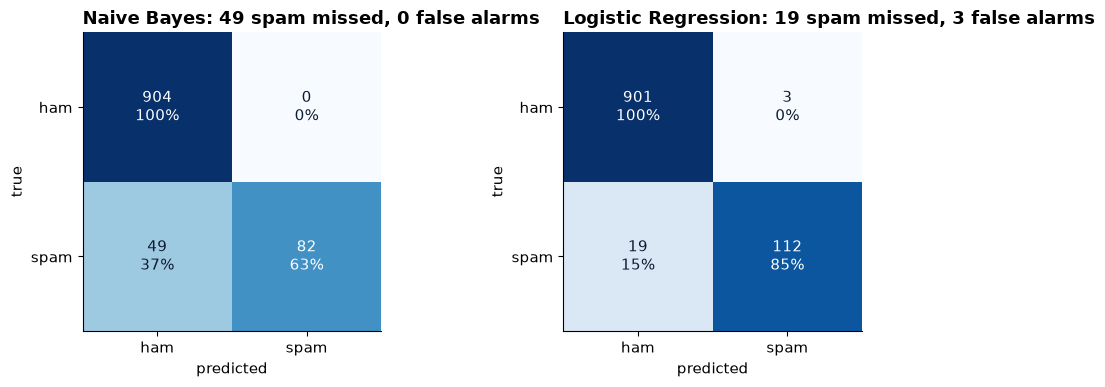

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, [("Naive Bayes", nb_filter), ("Logistic Regression", lr_filter)]):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=["ham", "spam"])
    plot_confusion(cm, ["ham", "spam"], ax=ax, title=f"{name}: {cm[1, 0]} spam missed, {cm[0, 1]} false alarms")
fig.tight_layout()
plt.show()

### 💬 Discussion — Which mistake is worse?
A **false alarm** (ham → spam folder) or a **missed spam** (spam in your inbox)? Would your answer change for a bank, a hospital, or a teenager's phone?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

For most people a false alarm is worse: a missed spam costs one second to delete, a hidden message from your doctor or your boss can cost a lot. That is why spam filters favour **precision** and usually send doubtful messages to a "spam" folder you can check, instead of deleting them. A bank that fights phishing may accept more false alarms (higher recall) because one successful scam is very expensive. Link to Lesson 02: the **threshold** is the knob that moves the balance (Exercise 4). The model does not decide this, the **cost of each error** does.
</details>

<a id="sec-8"></a>
# 8. 🔍 What did the model learn, and where does it fail?

A linear model gives **one weight per word**. A positive weight pushes towards *spam*, a negative one towards *ham*. Let's open the box: `top_coefficients` (in `src/text.py`) sorts the vocabulary by weight.

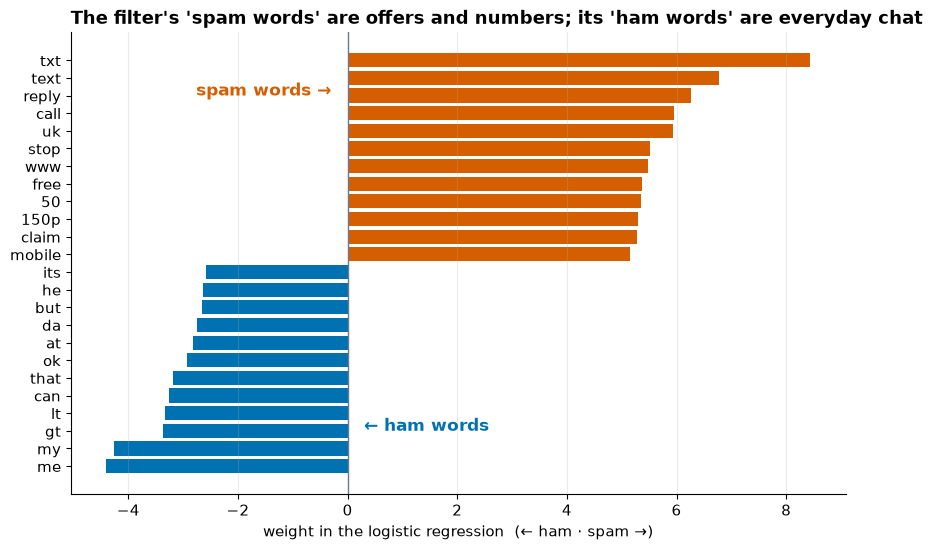

In [21]:
vec, clf = lr_filter.named_steps["tfidfvectorizer"], lr_filter.named_steps["logisticregression"]
top = top_coefficients(vec, clf, n=12)
top = top.sort_values("weight")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["word"], top["weight"], color=[CLASS_COLORS[c] for c in top["towards"]])
ax.axvline(0, color=PALETTE["grey"], lw=1)
ax.set(xlabel="weight in the logistic regression  (← ham · spam →)",
       title="The filter's 'spam words' are offers and numbers; its 'ham words' are everyday chat")
ax.grid(axis="y", visible=False)
ax.text(0.3, 2, "← ham words", color=CLASS_COLORS["ham"], ha="left", fontweight="bold", fontsize=12)
ax.text(-0.3, len(top) - 3, "spam words →", color=CLASS_COLORS["spam"], ha="right", fontweight="bold", fontsize=12)
plt.show()
save_slide(fig, "tm-spam-words")

Spam words are things like *txt*, *call*, *free*, *mobile*, *claim*, *uk*, *www*, and short codes. Ham words are *i*, *me*, *my*, *ok*, *ll*, *gt/lt* (from `&lt;#&gt;`, a placeholder this dataset uses in personal messages). Nobody gave the model a list of spam words: it **discovered** them from the labels.

Now the honest part: the mistakes.

In [22]:
proba = lr_filter.predict_proba(X_test)[:, list(lr_filter.classes_).index("spam")]
errors = pd.DataFrame({"text": X_test, "true": y_test, "predicted": lr_filter.predict(X_test), "P(spam)": proba})
missed = errors[(errors["true"] == "spam") & (errors["predicted"] == "ham")].sort_values("P(spam)")
false_alarms = errors[(errors["true"] == "ham") & (errors["predicted"] == "spam")]
print("❌ Spam the filter missed (lowest P(spam) first):")
display(missed.head(6)[["text", "P(spam)"]].round(3))   # round only for display
print("⚠️ Normal messages flagged as spam:")
display(false_alarms[["text", "P(spam)"]].round(3))

❌ Spam the filter missed (lowest P(spam) first):


,text,P(spam)
3890,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Da...",0.007
1423,Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 0909972639...,0.024
3743,ringtoneking 84484,0.031
5141,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT....,0.043
4185,Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min,0.057
2303,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about ...,0.066


⚠️ Normal messages flagged as spam:


,text,P(spam)
487,Are you free now?can i call now?,0.755
1620,Glad to see your reply.,0.735
4416,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to &...,0.719


The missed spam often **looks like a normal message**: no *free*, no *prize*, sometimes a friendly tone or a dating invitation. The false alarms (if any) contain spam-like words (*call*, *free*, numbers) in an innocent context. A bag of words sees the words, not the intention.

<a id="sec-9"></a>
# 9. ✍️ Try your own messages

Our `Pipeline` takes **raw text** in and gives a prediction out: tokenising, vocabulary, TF-IDF and the model all travel together. That is what "deploying" a text model looks like.

In [23]:
def check_sms(message, model=lr_filter):
    """Return the spam probability of one message, with a friendly verdict."""
    p = model.predict_proba([message])[0, list(model.classes_).index("spam")]
    verdict = "🚫 SPAM" if p >= 0.5 else "✅ ham"
    return f"{verdict}  (P(spam) = {p:.2f})  ←  {message}"

for message in ["Hey, are we still meeting for lunch tomorrow?",
                "URGENT! You have won a £1000 prize. Call 09061701461 now to claim",
                "Congratulations, you won a free ticket. Reply YES",
                "Can you call me when you are free?"]:
    print(check_sms(message))

✅ ham  (P(spam) = 0.00)  ←  Hey, are we still meeting for lunch tomorrow?
🚫 SPAM  (P(spam) = 1.00)  ←  URGENT! You have won a £1000 prize. Call 09061701461 now to claim
🚫 SPAM  (P(spam) = 0.84)  ←  Congratulations, you won a free ticket. Reply YES
✅ ham  (P(spam) = 0.07)  ←  Can you call me when you are free?


Want to type freely? Run the next cell and write in the box (it needs `ipywidgets`, available locally and in Colab). Try to **fool** the filter: write a spam that looks innocent, or a normal message that looks like spam.

In [24]:
import ipywidgets as widgets

box = widgets.Text(placeholder="Type an SMS and press Enter", continuous_update=False,
                   layout=widgets.Layout(width="90%"))
out = widgets.Output()

def on_enter(change):
    with out:
        print(check_sms(change["new"]))

box.observe(on_enter, names="value")   # runs when you press Enter
display(box, out)

Text(value='', continuous_update=False, layout=Layout(width='90%'), placeholder='Type an SMS and press Enter')

Output()

### ✏️ Exercise 3 — Count or TF-IDF for Naive Bayes? (Difficulty ⭐⭐)
Build `make_pipeline(CountVectorizer(), MultinomialNB())`, train it and add its scores to `results`. Naive Bayes was invented for **counts**: does it do better with counts than with TF-IDF here?

In [25]:
# TODO: a CountVectorizer + MultinomialNB pipeline, then compare with the leaderboard

<details>
<summary>💡 Show solution</summary>

```python
nb_counts = make_pipeline(CountVectorizer(), MultinomialNB()).fit(X_train, y_train)
results["Counts + Naive Bayes"] = spam_scores(y_test, nb_counts.predict(X_test))
pd.DataFrame(results).T.round(3)
```
With raw counts Naive Bayes **catches much more spam** (recall ≈ 0.89 instead of 0.63) for a small loss of precision (≈ 0.95 instead of 1.00), so its F1 goes up and it even edges out Logistic Regression. Its probabilities come from word counts, which is what the model was designed for. Lesson: the representation and the model go together; always try more than one combination.
</details>

### ✏️ Exercise 4 — A stricter filter (Difficulty ⭐⭐)
Use the probabilities `proba` (logistic regression, test set). With a threshold of **0.8** instead of 0.5, how many false alarms and how many missed spam do you get? And with **0.3**?

*(In a real project you would choose the threshold on validation data, not on the test set: Lesson 02, threshold tuning.)*

In [26]:
# TODO: for t in [0.3, 0.5, 0.8], count false alarms and missed spam

<details>
<summary>💡 Show solution</summary>

```python
true_spam = (y_test == "spam").to_numpy()
for t in [0.3, 0.5, 0.8]:
    flagged = proba >= t
    print(f"threshold {t}: false alarms = {(flagged & ~true_spam).sum():3d} · missed spam = {(~flagged & true_spam).sum():3d}")
```
A higher threshold makes the filter **more careful**: fewer false alarms, more missed spam. A lower threshold catches more spam but annoys users with false alarms. Same trade-off as in Lesson 02, now with text.
</details>

### ✏️ Exercise 5 — Characters instead of words (Difficulty ⭐⭐⭐)
Spammers write *"FR33 pr1ze"* to dodge word filters. Try `TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))` (pieces of 2 to 5 characters) with `LogisticRegression(C=10, max_iter=1000)`. Is it better? Compare `check_sms("You are a w1nner! Cl4im your FR33 pr1ze")` with both models.

In [27]:
# TODO: a character n-gram pipeline

<details>
<summary>💡 Show solution</summary>

```python
char_filter = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5)),
                            LogisticRegression(C=10, max_iter=1000)).fit(X_train, y_train)
results["Char 2-5 grams + LogReg"] = spam_scores(y_test, char_filter.predict(X_test))
display(pd.DataFrame(results).T.round(3))
tricky = "You are a w1nner! Cl4im your FR33 pr1ze"
print(check_sms(tricky, model=lr_filter))
print(check_sms(tricky, model=char_filter))
```
Here character n-grams are **better** than words (F1 for spam ≈ 0.94 vs 0.91) and **more robust to spelling tricks**: *pr1ze* still shares pieces like *pr* and *ze* with *prize*, so P(spam) for the tricky message roughly doubles (≈ 0.15 → 0.31). Not enough to cross 0.5: robustness helps, it is not magic. The price: many more columns (slower, more memory).
</details>

<a id="sec-10"></a>
# 10. 📌 Summary

| Idea | In one line |
|---|---|
| Tokens & vocabulary | Cut text into words; every different word becomes a column |
| Bag of words | A text = how many times each word appears (order is lost, most cells are 0) |
| TF-IDF | Count × rarity: words that are frequent here but rare elsewhere weigh more |
| Cosine similarity | The angle between two text vectors: 1 = same words, 0 = nothing in common |
| Naive Bayes | Adds up the "spam evidence" of each word; very fast, high precision |
| Logistic Regression | One weight per word; we can read its spam and ham words |
| Pipeline | Vectoriser + model learn together, only from the training data, and take raw text in |

**✅ Checklist:**
- [ ] I removed duplicates **before** splitting train and test.
- [ ] The vectoriser is **inside** the pipeline (fit on train only).
- [ ] I compared with the "always the majority class" baseline.
- [ ] I chose the positive class (spam) and looked at precision **and** recall.
- [ ] I read the model's top words and some of its mistakes.

<a id="sec-11"></a>
# 11. 📚 Learn more

> 📚 **Learn more**
> - scikit-learn User Guide: [Text feature extraction (bag of words, TF-IDF)](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction) · [Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html) · [Working with text data (tutorial)](https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html)
> - Jurafsky & Martin, *Speech and Language Processing* (3rd ed. draft, free online): [chapter "Naive Bayes, Text Classification and Sentiment"](https://web.stanford.edu/~jurafsky/slp3/) and the chapter on vector semantics (TF-IDF, cosine).
> - Almeida, Hidalgo & Yamakami (2011). *Contributions to the study of SMS spam filtering: new collection and results*. ACM DocEng. (The paper behind our dataset.)
>
> 🤖 **Link to modern AI:** large language models also start by cutting text into tokens and building a vocabulary; the difference is that each token becomes a *learned* vector instead of a count. Notebook 02 makes that jump.

---
<div align="center">

⬅️ [Previous: Lesson 02 · Machine Learning fundamentals](https://github.com/the-ai-learning-hub/02-machine-learning-fundamentals) &nbsp;·&nbsp; 🏠 [Lesson 03](../../README.md) &nbsp;·&nbsp; [Next: 02 · Tweet sentiment analysis](../02_project_tweets/02_Tweet_Sentiment_Analysis.ipynb) ➡️

**The AI Learning Hub** · Lesson 03 — Applied AI: unstructured data<br>
MIT License

</div>